# Why projects slip

*Beyond the scriptum — an application.*

---

Every task in a project has an estimated duration. The estimates are honest — on average they are
right, sometimes the task finishes early, sometimes late. Yet the project almost never meets the
deadline computed from the averages.

It is not incompetence or pessimism. It is **mathematics**:

$$E\big[\max(X_1, \dots, X_n)\big] \;>\; \max\big(E X_1, \dots, E X_n\big).$$

A project waits for the **slowest** branch, and the maximum of random variables is systematically
larger than the maximum of their averages. The more parallel branches, the worse.

In one case this problem has an **exact solution** that makes the point plain: for $n$ independent
tasks with the distribution $\operatorname{Exp}(1)$,

$$E\big[\max\big] = H_n = 1 + \tfrac12 + \tfrac13 + \dots + \tfrac1n.$$

Every task takes 1 on average. Ten parallel tasks take on average **2.93**.

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def estimate(xs):
    n = len(xs)
    m = sum(xs) / n
    var = sum((x - m) ** 2 for x in xs) / (n - 1)
    return m, math.sqrt(var / n)


def check(name, mean, se, exact, k=5):
    print(f"{name}: {mean:.4f} +- {se:.4f}  (exact {exact:.4f})")
    assert abs(mean - exact) <= k * se, name


def harmonic(n):
    return sum(1.0 / k for k in range(1, n + 1))

## 1. Waiting for the slowest

The simplest possible project: $n$ tasks run **in parallel** and the project ends when the last one
finishes. Every task takes $\operatorname{Exp}(1)$, i.e. one unit of time on average.

The naive estimate says: all of them take 1 on average, so the project takes 1. The reality is
$H_n$.

  tasks  naive estimate                reality   exact $H_n$     slip
      1            1.00         1.0022 +- 0.0022        1.0000     1.0x
      2            1.00         1.4983 +- 0.0025        1.5000     1.5x


      3            1.00         1.8335 +- 0.0026        1.8333     1.8x


      5            1.00         2.2841 +- 0.0027        2.2833     2.3x


     10            1.00         2.9276 +- 0.0039        2.9290     2.9x
     20            1.00         3.5900 +- 0.0063        3.5977     3.6x


     50            1.00         4.4979 +- 0.0098        4.4992     4.5x


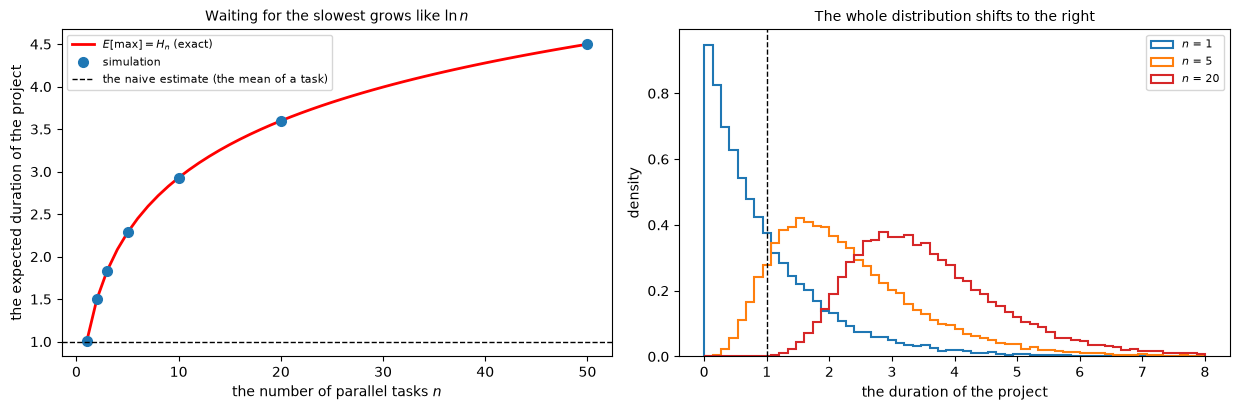

In [2]:
n_samples = 200_000
print(f"{'tasks':>7s} {'naive estimate':>15s} {'reality':>22s} {'exact $H_n$':>13s} {'slip':>8s}")
counts = (1, 2, 3, 5, 10, 20, 50)
actual = []
for n in counts:
    samples = [max(random.expovariate(1.0) for _ in range(n)) for _ in range(n_samples // max(1, n // 4))]
    m, se = estimate(samples)
    actual.append(m)
    print(f"{n:>7d} {1.0:>15.2f} {m:>14.4f} +- {se:.4f} {harmonic(n):>13.4f} {m / 1.0:>7.1f}x")
    assert abs(m - harmonic(n)) < 5 * se

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
nn = list(range(1, 51))
ax.plot(nn, [harmonic(n) for n in nn], "r-", lw=2, label="$E[\\max] = H_n$ (exact)")
ax.plot(counts, actual, "o", ms=7, label="simulation")
ax.axhline(1.0, color="k", ls="--", lw=1, label="the naive estimate (the mean of a task)")
ax.set_xlabel("the number of parallel tasks $n$")
ax.set_ylabel("the expected duration of the project")
ax.set_title("Waiting for the slowest grows like $\\ln n$", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
for n, color in ((1, "tab:blue"), (5, "tab:orange"), (20, "tab:red")):
    vals = [max(random.expovariate(1.0) for _ in range(n)) for _ in range(40_000)]
    w = 8 / 60
    ax.hist(vals, bins=60, range=(0, 8), weights=[1 / (len(vals) * w)] * len(vals),
            histtype="step", lw=1.5, color=color, label=f"$n$ = {n}")
ax.axvline(1.0, color="k", ls="--", lw=1)
ax.set_xlabel("the duration of the project")
ax.set_ylabel("density")
ax.set_title("The whole distribution shifts to the right", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Twenty parallel tasks, each one unit of time on average, take on average **3.6** units. No task was
late — it is just that we wait for whichever one was having a bad run.

The lesson for planning: **parallelization does not help as much as it seems.** Splitting the work
into twenty parallel branches does not cut the time to a twentieth, because the result is governed by
the slowest branch, and that one is the slower, the more branches you have.

## 2. A real project: a network of tasks

In practice the tasks are not all parallel — they are linked by dependencies. A project is modelled as
a **directed graph** in which an edge means "this has to finish before that can start". The duration
of the project is **the longest path** through the network (the critical path).

Let us take a small project of eight tasks. We model the durations by the triangular distribution
(exercise 4) — an optimistic, a most likely and a pessimistic estimate, exactly as the classical PERT
method does.

In [3]:
def triangular(a, c, b):
    '''The triangular distribution on [a, b] with the peak at c (exercise 4).'''
    g = random.random()
    threshold = (c - a) / (b - a)
    if g < threshold:
        return a + math.sqrt(g * (b - a) * (c - a))
    return b - math.sqrt((1.0 - g) * (b - a) * (b - c))


# a task: (name, predecessors, optimistic, most likely, pessimistic)
PROJECT = [
    ("analysis",     [],                        3,  5, 12),
    ("UI design",    ["analysis"],              2,  4,  9),
    ("API design",   ["analysis"],              3,  5,  8),
    ("frontend",     ["UI design"],             5,  8, 20),
    ("backend",      ["API design"],            6, 10, 18),
    ("database",     ["API design"],            2,  4, 11),
    ("integration",  ["frontend", "backend", "database"], 2, 4, 10),
    ("testing",      ["integration"],           3,  6, 15),
]
NAMES = [u[0] for u in PROJECT]


def project_duration(return_critical=False):
    '''The longest path through the network. Returns the duration, and optionally which task was last.'''
    end = {}
    for name, pred, a, c, b in PROJECT:
        start = max((end[p] for p in pred), default=0.0)
        end[name] = start + triangular(a, c, b)
    last = max(end, key=end.get)
    return (end[last], last) if return_critical else end[last]


# the naive estimate: all tasks at their mean
def naive():
    end = {}
    for name, pred, a, c, b in PROJECT:
        start = max((end[p] for p in pred), default=0.0)
        end[name] = start + (a + c + b) / 3
    return max(end.values())


N = 100_000
durations = [project_duration() for _ in range(N)]
m, se = estimate(durations)
sorted_d = sorted(durations)
print(f"the naive plan (every task at its mean): {naive():.2f} days")
print(f"simulation, the mean duration:           {m:.2f} +- {se:.2f} days")
print(f"                                         so {m / naive() - 1:.0%} longer\n")
for q in (0.5, 0.8, 0.9, 0.95, 0.99):
    print(f"  the deadline we meet with probability {q:4.0%}: {sorted_d[int(q * N)]:.1f} days")
print(f"\nThe naive plan is met in only {sum(1 for d in durations if d <= naive()) / N:.0%} of cases.")

the naive plan (every task at its mean): 36.67 days
simulation, the mean duration:           38.15 +- 0.01 days
                                         so 4% longer

  the deadline we meet with probability  50%: 38.0 days
  the deadline we meet with probability  80%: 42.0 days
  the deadline we meet with probability  90%: 44.1 days
  the deadline we meet with probability  95%: 45.9 days
  the deadline we meet with probability  99%: 49.0 days



The naive plan is met in only 38% of cases.


This is the heart of the matter. A plan computed from averages comes out optimistic and is **met only
in about a third of cases** — even though every single estimate was honest.

If you want a deadline you can promise, you have to take a **quantile**, not the mean. The simulation
gives it straight away, just like the capital the insurance company needs in exercise 9.

## 3. The critical path is not fixed

Classical planning determines a single "critical path" and guards it. But which branch becomes
critical is itself random — in every run a different task may cause the slip.

We compute **how often each task is the last one**, and how much its delay matters.

How often a task lies on the critical path:
   integration  100.0%
       testing  100.0%
      analysis  100.0%
    API design   57.5%
       backend   56.3%
     UI design   42.5%
      frontend   42.5%
      database    1.2%

The tasks at 100 % always lie on the critical path (they have no parallel alternative).
The interesting ones are those in between: which of the branches frontend / backend / database
is holding things up changes from run to run — and that is exactly why one cannot guard just one fixed path.

the baseline mean duration: 38.20 days

What we gain when we speed up ONE task by 20 %:


       testing   1.60 days
      analysis   1.36 days
       backend   1.18 days
   integration   1.07 days
      frontend   0.94 days
    API design   0.60 days
     UI design   0.43 days
      database   0.04 days


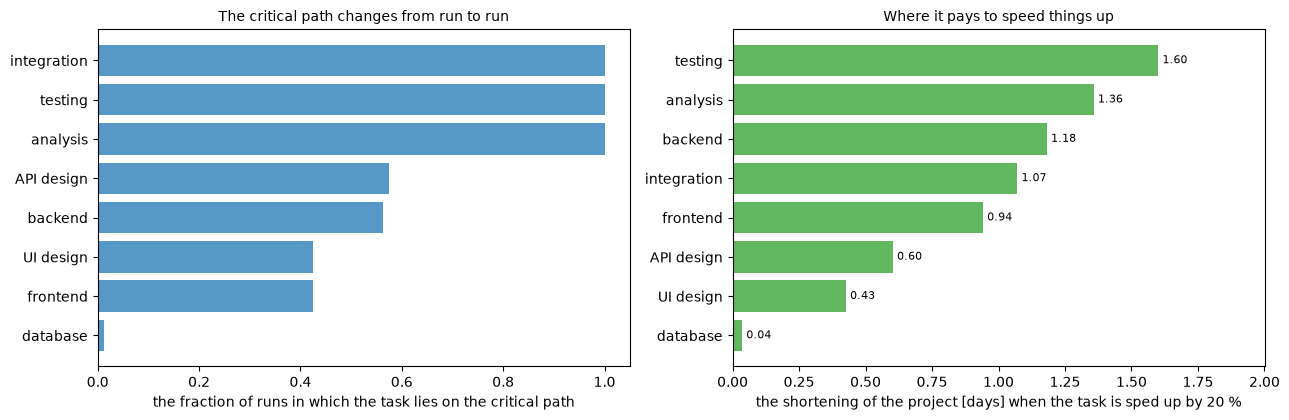

In [4]:
from collections import Counter

PREDECESSORS = {name: pred for name, pred, *_ in PROJECT}


def critical_path():
    '''One run; returns (the project duration, the set of tasks on the critical path).

    We find the critical path backwards: from the last task we always jump to the
    predecessor that finished latest — it is the one that decided when work could start.
    '''
    end = {}
    for name, pred, a, c, b in PROJECT:
        start = max((end[p] for p in pred), default=0.0)
        end[name] = start + triangular(a, c, b)
    node = max(end, key=end.get)
    path = set()
    while node is not None:
        path.add(node)
        pred = PREDECESSORS[node]
        node = max(pred, key=end.get) if pred else None
    return end[max(end, key=end.get)], path


on_path = Counter()
M_ = 60_000
for _ in range(M_):
    _, path = critical_path()
    on_path.update(path)

print("How often a task lies on the critical path:")
for name, count in on_path.most_common():
    print(f"  {name:>12s} {count / M_:>7.1%}")
print("\nThe tasks at 100 % always lie on the critical path (they have no parallel alternative).")
print("The interesting ones are those in between: which of the branches frontend / backend / database")
print("is holding things up changes from run to run — and that is exactly why one cannot guard just one fixed path.")

# sensitivity: by how much the project shortens when we speed up one task by 20 %
baseline = sum(project_duration() for _ in range(40_000)) / 40_000
print(f"\nthe baseline mean duration: {baseline:.2f} days")
print("\nWhat we gain when we speed up ONE task by 20 %:")
gains = {}
for i, (name, pred, a, c, b) in enumerate(PROJECT):
    original = PROJECT[i]
    PROJECT[i] = (name, pred, a * 0.8, c * 0.8, b * 0.8)
    new = sum(project_duration() for _ in range(40_000)) / 40_000
    PROJECT[i] = original
    gains[name] = baseline - new
for name, g in sorted(gains.items(), key=lambda kv: -kv[1]):
    print(f"  {name:>12s} {g:>6.2f} days")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
nm = [n for n, _ in on_path.most_common()]
ax.barh(nm, [on_path[n] / M_ for n in nm], color="tab:blue", alpha=0.75)
ax.set_xlabel("the fraction of runs in which the task lies on the critical path")
ax.set_title("The critical path changes from run to run", fontsize=10)
ax.invert_yaxis()

ax = axes[1]
nm2 = sorted(gains, key=lambda n: gains[n])
b = ax.barh(nm2, [gains[n] for n in nm2], color="tab:green", alpha=0.75)
ax.bar_label(b, fmt="%.2f", padding=3, fontsize=8)
ax.set_xlabel("the shortening of the project [days] when the task is sped up by 20 %")
ax.set_xlim(right=max(gains.values()) * 1.25)
ax.set_title("Where it pays to speed things up", fontsize=10)
plt.tight_layout()
plt.show()

The right-hand plot is the practical answer to "where do I put the extra people". Speeding up a task
that is almost never last barely helps the project at all — while the same investment in the
bottleneck shows up directly.

And the left-hand plot explains why the classical critical path misleads. The tasks with no parallel
alternative (analysis, integration, testing) always lie on the critical path — those are boring. The
interesting ones are the trio **frontend / backend / database**: each of them becomes critical only
sometimes, depending on which one is having a bad run. **No single path is critical all the time**, so
guarding only the nominally longest one means overlooking the branches that become critical in an
unfavourable run.

## Summary

| Concept | What to remember |
|---------|------------------|
| The core of the problem | $E[\max] > \max E$ — the project waits for the slowest branch |
| The exact check | $n$ tasks $\operatorname{Exp}(1)$ in parallel ⟹ $E[\max] = H_n$ |
| Parallelization | twenty branches of one unit each take $3.6$, not $1$ |
| A plan from averages | systematically optimistic; met in only about a third of cases |
| A deadline you can promise | a **quantile**, not the mean — just like the insurance company's capital |
| The critical path | not fixed, it changes from run to run |
| Where to invest | where a task is often last, not where it is nominally longest |

The connection with the rest of the repository: it is Jensen's inequality in practice. In
`branching_process` feedback decided, here it is the **maximum** — and both are cases where the
expectation of the result is not the result of the expectations.

### Try it yourself

1. Verify $E[\max] = H_n$ for tasks with a different distribution of mean 1 as well (a uniform one on
   $[0,2]$, say). Does the formula hold? Why not?
2. Add a **dependence between the tasks** to the project (if the analysis is delayed, everything is).
   How does the variance of the project duration change?
3. Compute by how much the 95 % deadline moves when you double the pessimistic estimates, and compare
   it with the shift of the mean.
4. Try the "student syndrome": a task never finishes earlier than planned (the left part of the
   distribution is truncated). By how much does the project lengthen?
5. Split a large task into two parallel half-sized ones. Does the project shorten by half? (Hint: look
   at $H_2$.)
6. Instead of the triangular distribution use a lognormal one with the same mean and variance. How
   much does the shape of the tail matter?